In [1]:
import numpy as np
import matplotlib.pyplot as plt
import importlib
import stochastic_model_v1 as mfa

In [ ]:
#MTD parameters
#simulation parameter
T = 1
#k_B = 1 assumed here
deltaT = 7*T

gw1 = mfa.gaussian_well_1(10,1)

padfactor = 15
n_bins = 300
x = np.linspace(-padfactor*gw1.stdev(), padfactor*gw1.stdev(), n_bins)
F = gw1.f1(x)

plt.plot(x,F)
plt.axvline(gw1.stdev(), linestyle="dashed", color="black")
plt.axvline(gw1.xlim(), linestyle="dashed", color="black")


well depth =  7.2
well curvature =  0.96
deltaT = 13.4


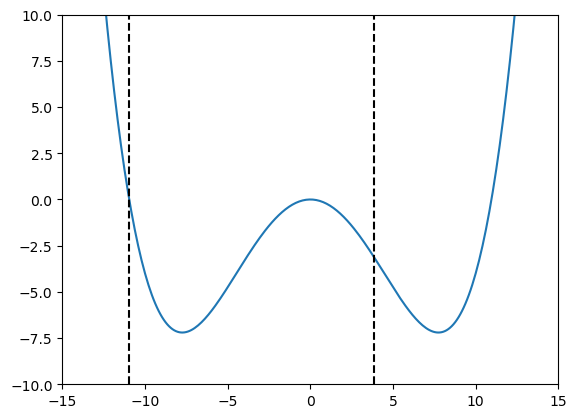

In [2]:
importlib.reload(mfa)

#MTD parameters
#simulation parameter
T = 1
#k_B = 1 assumed here

dw1 = mfa.double_well_1(0.002,120)

print("well depth = ", dw1.depth())

print("well curvature = ", dw1.sec_deriv_bottom())

deltaT = 2*dw1.depth()-T
print(f"deltaT = {deltaT}")

padfactor = 4
n_bins = 300
x = np.linspace(-padfactor*dw1.stdev(), padfactor*dw1.stdev(), n_bins)
F = dw1.f1(x)

plt.plot(x,F)
plt.axvline(dw1.stdev(), linestyle="dashed", color="black")
plt.axvline(dw1.xlim(), linestyle="dashed", color="black")
plt.ylim(-10,10)
plt.xlim(-15,15)

sysname = "double_well_1"


well depth =  6
well curvature =  3
deltaT = 11


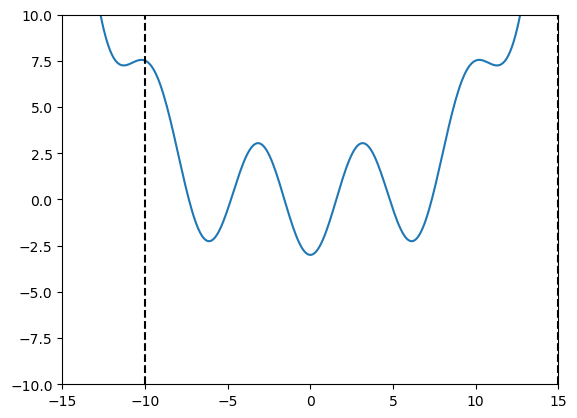

In [2]:
importlib.reload(mfa)

#MTD parameters
#simulation parameter
T = 1
#k_B = 1 assumed here

dw1 = mfa.sine_well_1(0.0005, 3, 1)

print("well depth = ", dw1.depth())

print("well curvature = ", dw1.sec_deriv_bottom())

deltaT = 2*dw1.depth()-T
print(f"deltaT = {deltaT}")

padfactor = 1
n_bins = 300
x = np.linspace(-padfactor*dw1.stdev(), padfactor*dw1.stdev(), n_bins)
F = dw1.f1(x)

plt.plot(x,F)
plt.axvline(dw1.stdev(), linestyle="dashed", color="black")
plt.axvline(dw1.xlim(), linestyle="dashed", color="black")
plt.ylim(-10,10)
plt.xlim(-15,15)

sysname = "sine_well_1"

well depth =  6
well curvature =  6.75
deltaT = 11


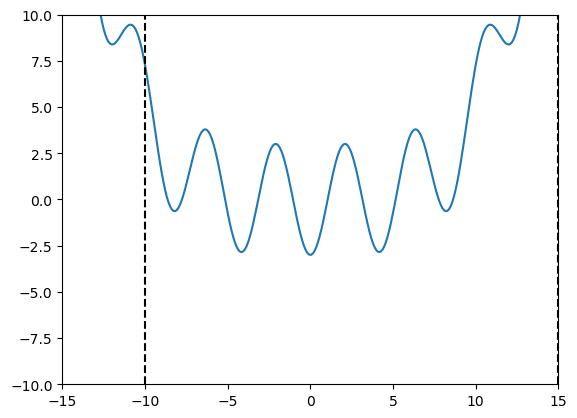

In [81]:
importlib.reload(mfa)

#MTD parameters
#simulation parameter
T = 1
#k_B = 1 assumed here

dw1 = mfa.sine_well_1(0.0005, 3, 1.5)

print("well depth = ", dw1.depth())

print("well curvature = ", dw1.sec_deriv_bottom())

deltaT = 2*dw1.depth()-T
print(f"deltaT = {deltaT}")

padfactor = 1
n_bins = 300
x = np.linspace(-padfactor*dw1.stdev(), padfactor*dw1.stdev(), n_bins)
F = dw1.f1(x)

plt.plot(x,F)
plt.axvline(dw1.stdev(), linestyle="dashed", color="black")
plt.axvline(dw1.xlim(), linestyle="dashed", color="black")
plt.ylim(-10,10)
plt.xlim(-15,15)

sysname = "sine_well_2"

In [ ]:
importlib.reload(mfa)

#MTD parameters
#simulation parameter
T = 1
#k_B = 1 assumed here

dw1 = mfa.sine_well_1(0.0005, 3, 2)

print("well depth = ", dw1.depth())

print("well curvature = ", dw1.sec_deriv_bottom())

deltaT = 2*dw1.depth()-T
print(f"deltaT = {deltaT}")

padfactor = 1
n_bins = 300
x = np.linspace(-padfactor*dw1.stdev(), padfactor*dw1.stdev(), n_bins)
F = dw1.f1(x)

plt.plot(x,F)
plt.axvline(dw1.stdev(), linestyle="dashed", color="black")
plt.axvline(dw1.xlim(), linestyle="dashed", color="black")
plt.ylim(-10,10)
plt.xlim(-15,15)

sysname = "sine_well_3"

100 gaussians deposited
gaussian deposition rate: 21.407801933104228
testing 109 different gaussian widths
simulating for sigma = 0.1


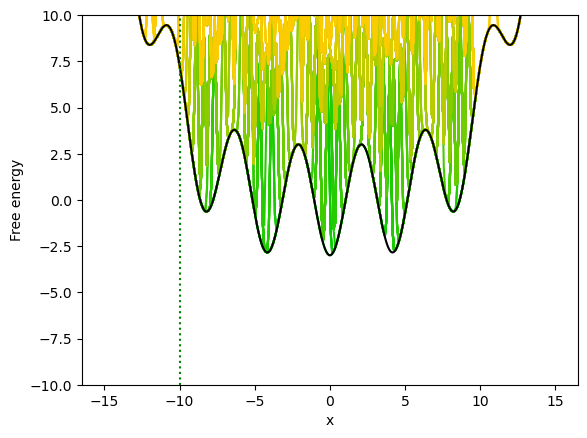

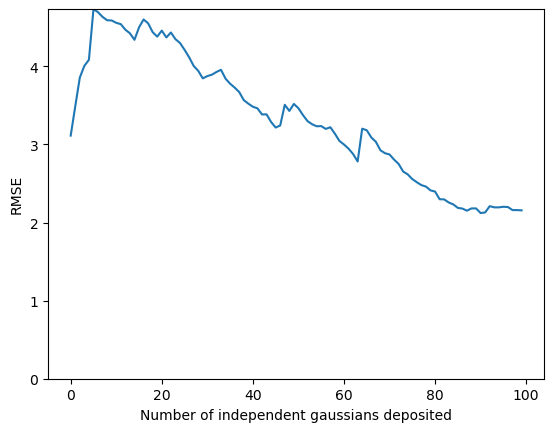

simulating for sigma = 0.7999999999999999


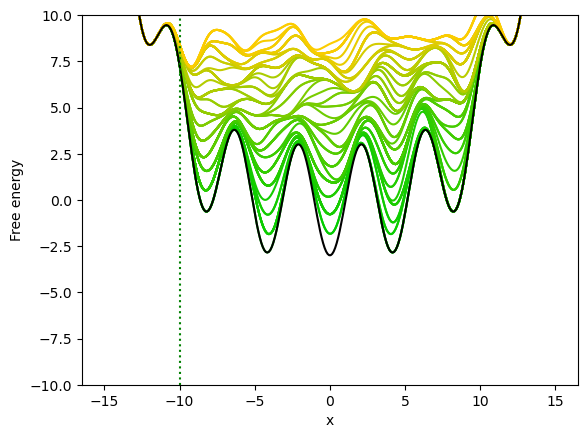

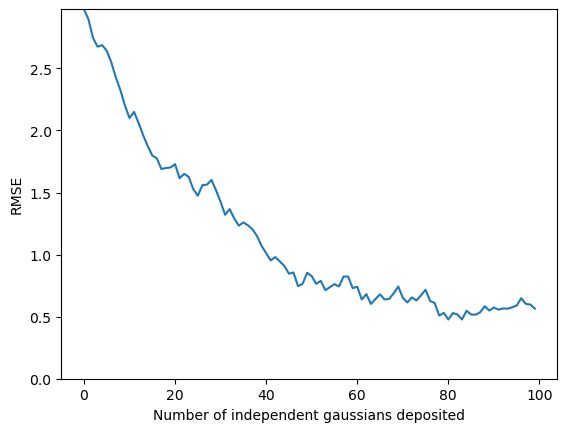

simulating for sigma = 1.5


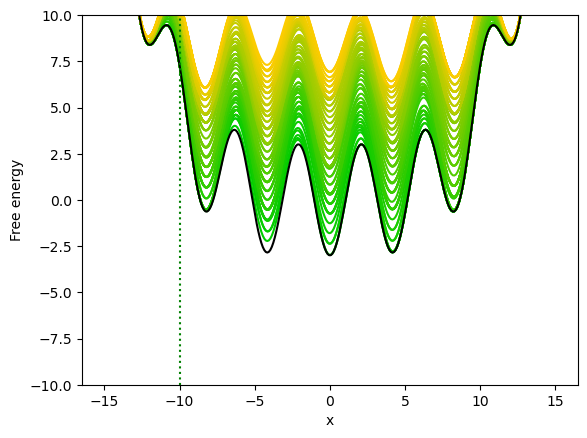

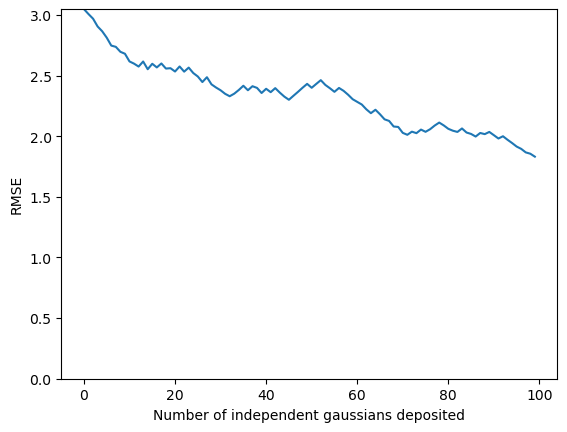

500 gaussians deposited
gaussian deposition rate: 4.281560386620845
testing 80 different gaussian widths
simulating for sigma = 0.1


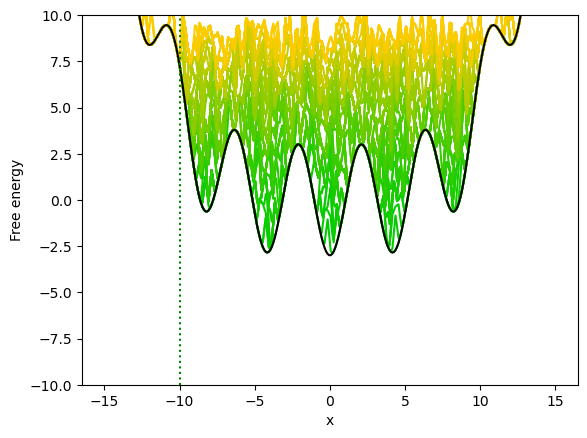

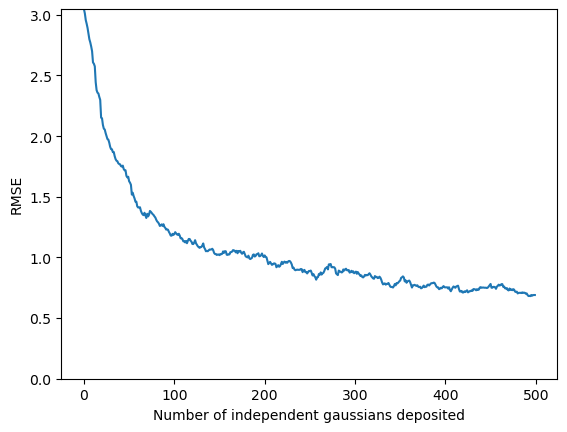

simulating for sigma = 0.8088607594936708


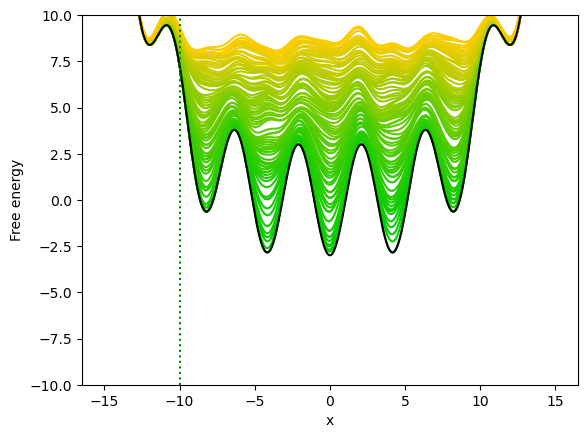

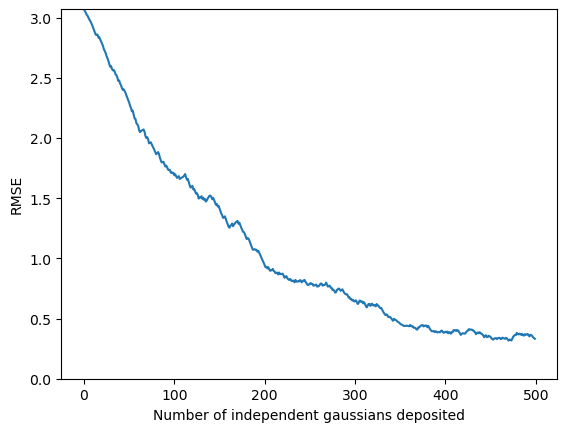

simulating for sigma = 1.5


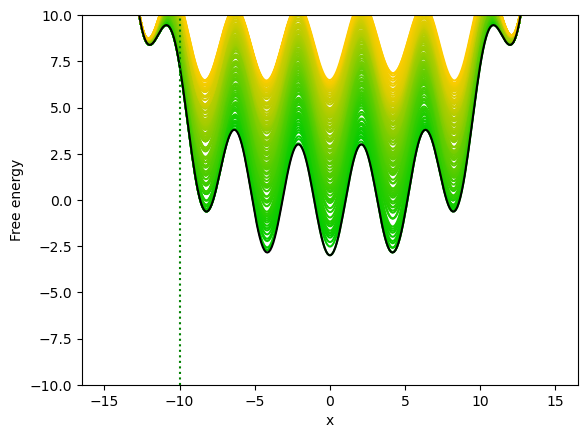

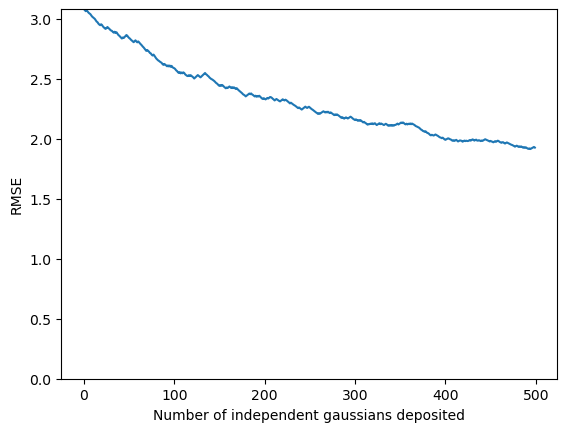

750 gaussians deposited
gaussian deposition rate: 2.854373591080564
testing 76 different gaussian widths
simulating for sigma = 0.1


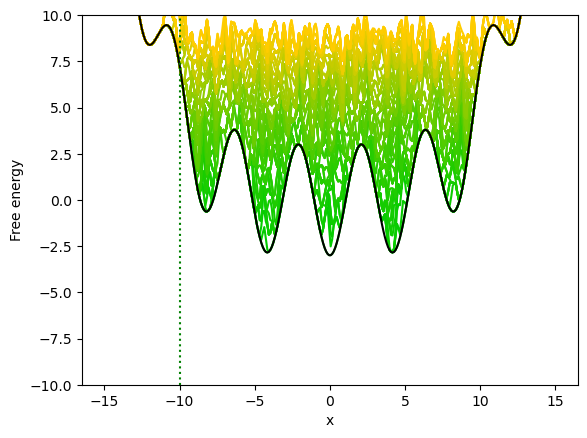

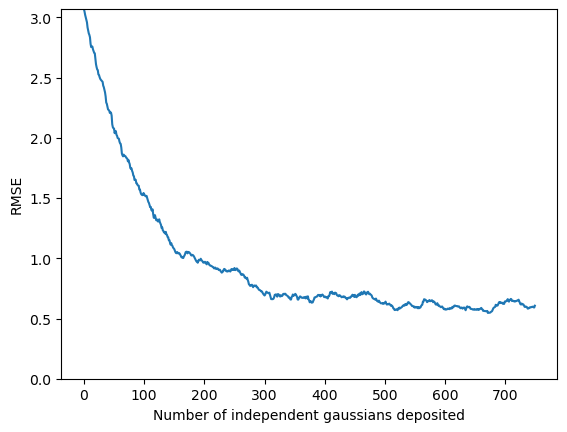

simulating for sigma = 0.8093333333333332


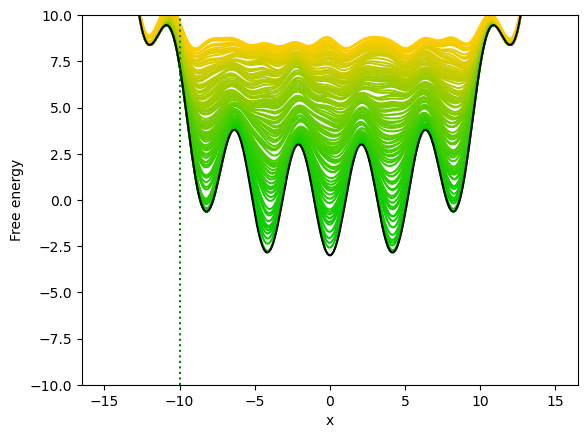

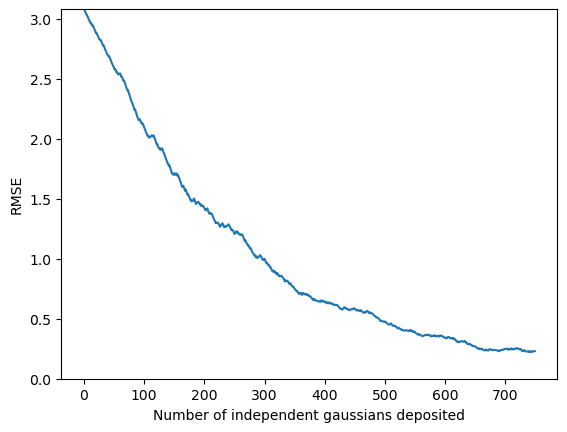

simulating for sigma = 1.5


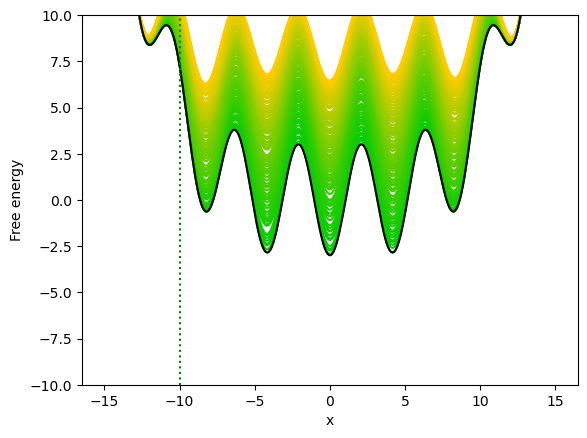

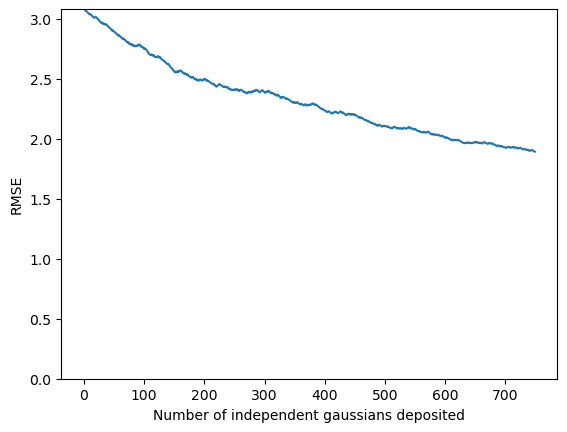

1000 gaussians deposited
gaussian deposition rate: 2.1407801933104227
testing 72 different gaussian widths
simulating for sigma = 0.1


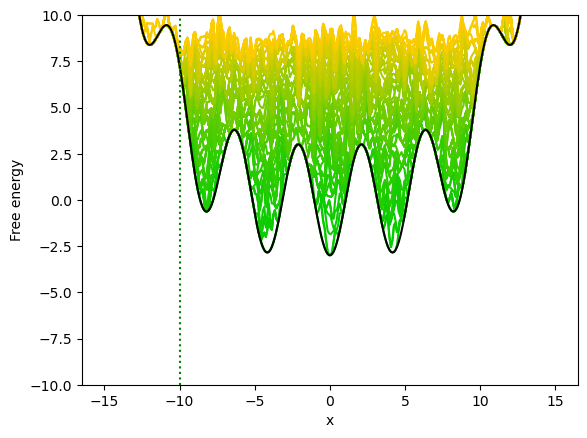

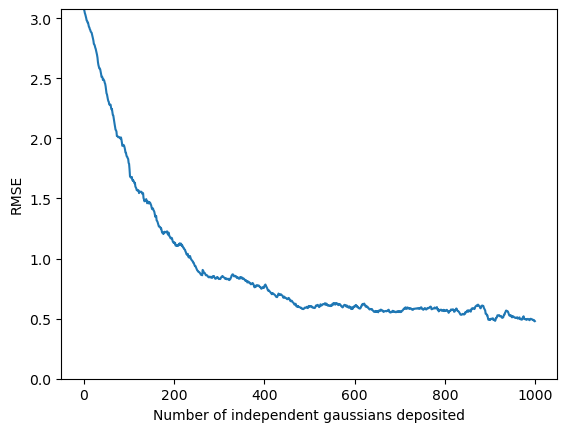

simulating for sigma = 0.8098591549295774


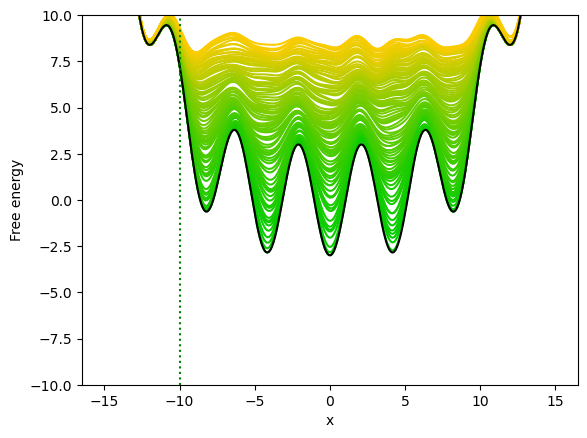

In [ ]:
importlib.reload(mfa)

#make sure that the cell for the relevant system has been run most recently to avoid overwriting padfactor and x and such

base_n_sigmas = 500
sigma_min = 0.1
sigma_max = 1.5
#print(len(sigmas))

all_nrounds = [100,500,750,1000,1500,2000,3500,5000,10000] #,20000]

rmses_all_n = []
sigmas_all_n = []

for nrounds in all_nrounds:
    omega = n_bins*deltaT*(np.exp(1/2)-1)/nrounds
    print(f"{nrounds} gaussians deposited")
    print(f"gaussian deposition rate: {omega}")

    n_sigmas = int(round(base_n_sigmas/np.log(nrounds)))
    print(f"testing {n_sigmas} different gaussian widths")
    sigmas = np.linspace(sigma_min, sigma_max, n_sigmas)
    
    rmses = []

    for i_s, sigma in enumerate(sigmas):
        #print(f"simulating for sigma = {sigma}")
        plot_output = (i_s==int(n_sigmas/2) or i_s == 0 or i_s == n_sigmas-1)
        if plot_output:
            print(f"simulating for sigma = {sigma}")
        rmse, time, nrounds = mfa.simulate(dw1, T, sigma, omega, deltaT, x=x, nrounds=nrounds, threshold = 10**-3, plot=plot_output)
        rmses.append(rmse)

    rmses_all_n.append(rmses)
    sigmas_all_n.append(sigmas)

final_errors = [[np.mean(r[-int(nrounds/20):-1]) for r in rmse_list] for rmse_list in rmses_all_n]

minima = []
minimum_rmses = []

ii=0
for fe, sigmas in zip(final_errors, sigmas_all_n):
    #plt.plot(sigmas, fe, color = [ii/len(all_nrounds), 0, 1-ii/len(all_nrounds)])
    minimum_sigma, minimum_rmse = mfa.fit_cubic_minimum(sigmas, fe, plot=True)
    plt.show()
    minima.append(minimum_sigma)
    minimum_rmses.append(minimum_rmse)
    ii += 1


plt.plot(all_nrounds, minima)
plt.xlabel("number of gaussians")
plt.ylabel("optimal gaussian width")
plt.show()

plt.plot(all_nrounds, minimum_rmses)
plt.xlabel("number of gaussians")
plt.ylabel("RMSE at optimal gaussian width")
plt.show()

plt.scatter(all_nrounds, minima)
predicted_widths = [(2*np.sqrt(np.pi)*-2*dw1.xlim()*((1/2)*dw1.sec_deriv_bottom()**2)*nr)**(-1/5) for nr in all_nrounds]
plt.plot(all_nrounds, predicted_widths, color="orange")
#plt.plot(all_nrounds, [3.5*((dw1.depth()/(np.sqrt(2*np.pi)*dw1.sec_deriv_bottom()))**(1/3))*(nr**(-1/5)) for nr in all_nrounds], color="red")
plt.xlabel("Number of gaussians")
plt.ylabel("Optimal gaussian width")
plt.ylim(0, max(max(predicted_widths), max(minima)))
plt.savefig(f"opt_gauss_widths_{sysname}")
plt.show()

np.save(f"opt_gauss_widths_{sysname}.npy", np.stack([all_nrounds, minima]))

#plt.scatter(all_nrounds, minima)
ogwrs = [pwi / minimum for pwi, minimum in zip(predicted_widths, minima)]
plt.plot(all_nrounds, ogwrs, color="orange")
#plt.plot(all_nrounds, [3.5*((dw1.depth()/(np.sqrt(2*np.pi)*dw1.sec_deriv_bottom()))**(1/3))*(nr**(-1/5)) for nr in all_nrounds], color="red")
plt.xlabel("Number of gaussians")

plt.ylabel("Optimal gaussian width ratio")
plt.ylim(0,max(ogwrs))
plt.savefig(f"opt_gauss_widths_ratio_{sysname}")
plt.show()


# plt.legend(all_nrounds, title="N gaussians")

# plt.xlabel("MTD gaussian width / well width")
# plt.ylabel("Final RMSE")

#final_errors_normalized = np.array(final_errors)/np.max(np.array(final_errors), axis=1, keepdims=True)
#plt.imshow(final_errors_normalized, aspect="auto", extent=[sigma_min, sigma_max, all_nrounds[-1], all_nrounds[0]], cmap="viridis")
#plt.colorbar()
#plt.xlabel("MTD gaussian width / well width")
#plt.ylabel("Number of independent gaussians deposited")


In [ ]:
plt.scatter(all_nrounds, minima)
plt.plot(all_nrounds, [(2*np.sqrt(np.pi)*-2*dw1.xlim()*(dw1.sec_deriv_bottom()**2)*nr)**(-1/5) for nr in all_nrounds], color="orange")
plt.plot(all_nrounds, [3.5*((dw1.depth()/(np.sqrt(2*np.pi)*dw1.sec_deriv_bottom()))**(1/3))*(nr**(-1/5)) for nr in all_nrounds], color="red")

plt.xlabel("Number of gaussians")
plt.ylabel("Optimal gaussian width")
plt.show()

In [ ]:
final_errors = [[r[-1] for r in rmse_list] for rmse_list in rmses_all_n]

for fe, sigmas in zip(final_errors, sigmas_all_n):
    plt.plot(sigmas, fe)

plt.xlabel("MTD gaussian width / well width")
plt.ylabel("Final RMSE")

In [ ]:
# plt.plot(all_nrounds, optimal_sigmas)
# plt.xlabel("Number of gaussians")
# plt.ylabel("Optimal Sigma/well_sigma")

In [ ]:
importlib.reload(mfa)

minima = []
minimum_rmses = []

ii=0
for fe, sigmas in zip(final_errors, sigmas_all_n):
    print(ii)
    plt.plot(sigmas, fe, color = [ii/len(all_nrounds), 0, 1-ii/len(all_nrounds)])
    minimum_sigma, minimum_rmse = mfa.fit_cubic_minimum(sigmas, fe, plot=True)
    plt.show()
    minima.append(minimum_sigma)
    minimum_rmses.append(minimum_rmse)
    ii += 1

In [ ]:
plt.plot(all_nrounds, minima)